# 07 · A bicycle ride, an incident and an ambulance journey

**How can we reconstruct a sequence of events from a GPX recording?**

The instructor's account supplies the context: a person went for a bicycle ride, had an incident, waited for assistance and was taken by ambulance to an emergency department. The recording follows the device through that journey. The GPX contains positions and times, not labels saying “collision”, “ambulance arrival” or “hospital admission”.

We first explore the whole route without assigning phases. Then we look for a long spatially concentrated interval, inspect the preceding speed changes, examine speeds 5, 10, 15, 30 and 60 seconds before a candidate event time, and compare movement before and after the wait. Maps, timestamped samples and recording gaps must support the interpretation together.

**Learning goals:** read GPX tracks and segments; preserve timestamps; construct a MovingPandas trajectory; derive interval speeds; detect a candidate stop; inspect temporal coverage; reconstruct pre-event movement; distinguish an inferred transition from a confirmed event.

Calculations retain the original UTC reference.<br/> **Maps, timelines and event tables show Europe/Rome local time**. <br/>On **12 October 2021**, Rome used CEST (**UTC+02:00**): 13:41:52 UTC is 15:41:52 in Rome. <br/>Use timezone conversion; do not manually add two hours or relabel UTC as local time.<br/> All interactive maps use HOT OSM. No map matching or trajectory simplification is applied before measuring speed.


In [28]:
%pip install -q gpxpy movingpandas geopandas folium mapclassify matplotlib requests

In [29]:
from pathlib import Path
import json
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
import matplotlib.pyplot as plt
from IPython.display import display
DATA = Path("data")
DATA.mkdir(exist_ok=True)

import gpxpy
import movingpandas as mpd
from datetime import timedelta

## 1. Read the GPX, not just its map

A GPX may contain wpt, rte or trk. A track can have several segments, which should not be silently joined across gaps.

**Colab AI prompt:** Download strava_full.gpx from the linked source Gist. Show an XML excerpt and the counts of tracks, segments and points.

In [30]:
gpx_url = "https://gist.githubusercontent.com/napo/4d0c14585da0ef96f263faa0e8d97ff5/raw/efba18f806459b462a1e485023cdd01c4d20e01a/strava_full.gpx"
gpx_path = DATA / "strava_full.gpx"
if not gpx_path.exists():
    response = requests.get(gpx_url, timeout=40)
    response.raise_for_status()
    gpx_path.write_bytes(response.content)
gpx_text = gpx_path.read_text()
print(gpx_text[:800])
gpx = gpxpy.parse(gpx_text)
print("Creator:", gpx.creator)
print("Waypoints:", len(gpx.waypoints), "Routes:", len(gpx.routes), "Tracks:", len(gpx.tracks))
for track_number, track in enumerate(gpx.tracks):
    print("Track", track_number, "segment lengths:", [len(s.points) for s in track.segments])

﻿<?xml version="1.0" encoding="UTF-8" standalone="no" ?>
<gpx xmlns="http://www.topografix.com/GPX/1/1" xmlns:gpxx="http://www.garmin.com/xmlschemas/GpxExtensions/v3" xmlns:gpxtpx="http://www.garmin.com/xmlschemas/TrackPointExtension/v1" creator="https://www.mapstogpx.com/strava" version="1.1" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xsi:schemaLocation="http://www.topografix.com/GPX/1/1 http://www.topografix.com/GPX/1/1/gpx.xsd http://www.garmin.com/xmlschemas/GpxExtensions/v3 http://www.garmin.com/xmlschemas/GpxExtensionsv3.xsd http://www.garmin.com/xmlschemas/TrackPointExtension/v1 http://www.garmin.com/xmlschemas/TrackPointExtensionv1.xsd" xmlns:gpxdata="http://www.cluetrust.com/XML/GPXDATA/1/0">
 <metadata>
  <name>Giro col botto. 😁</name>
  <author>
   <name></name>
   <l
Creator: https://www.mapstogpx.com/strava
Waypoints: 0 Routes: 0 Tracks: 1
Track 0 segment lengths: [5532]


GPX positions use WGS84 longitude/latitude. Inspect the source's elevation reference before treating elevations as comparable with another height dataset. Timestamps can include UTC or a timezone offset. Preserve that information: local clock time and UTC are different labels for the same instant.

[GPX 1.1 specification](https://www.topografix.com/GPX/1/1/) · [MovingPandas documentation](https://movingpandas.readthedocs.io/en/v0.23.0/).

This timestamped GPX supports interval-speed estimates. The position-only GPX in 06 does not. Export-generated timestamps cannot replace the original recording times.


## 2. Inspect a recorded point

Look at latitude, longitude, elevation and time before making a table.

**Colab AI prompt:** Select the first track segment and inspect its first point. Keep segment boundaries explicit.

In [31]:
segment = gpx.tracks[0].segments[0]
point = segment.points[0]
print("Latitude:", point.latitude, "Longitude:", point.longitude)
print("Elevation:", point.elevation, "Timestamp:", point.time)
print("Points in the selected segment:", len(segment.points))

Latitude: 45.900222 Longitude: 10.847826
Elevation: 96.5 Timestamp: 2021-10-12 12:01:38+00:00
Points in the selected segment: 5532


## 3. Build a readable table

Keep source sequence and time. Do not sort or remove duplicates before inspecting them.

**Colab AI prompt:** Build gpx_tracks from the selected segment with longitude, latitude, altitude and time; parse time with utc=True.

In [32]:
# Keep the order of the points as recorded in this GPX segment.
rows = []
for sequence, point in enumerate(segment.points):
    rows.append({"sequence": sequence, "longitude": point.longitude,
        "latitude": point.latitude, "altitude": point.elevation, "time": point.time})
gpx_tracks = pd.DataFrame(rows)
gpx_tracks["time"] = pd.to_datetime(gpx_tracks["time"], utc=True)
gpx_tracks["time_Italy"] = gpx_tracks["time"].dt.tz_convert("Europe/Rome")
display(gpx_tracks.head())
print("First/last:", gpx_tracks["time"].min(), gpx_tracks["time"].max())
print("Missing times:", gpx_tracks["time"].isna().sum())
print("Repeated times:", gpx_tracks["time"].duplicated().sum())
print("Source order is chronological:", gpx_tracks["time"].is_monotonic_increasing)

,sequence,longitude,latitude,altitude,time,time_Italy
0,0,10.847826,45.900222,96.5,2021-10-12 12:01:38+00:00,2021-10-12 14:01:38+02:00
1,1,10.847850,45.900264,96.5,2021-10-12 12:01:39+00:00,2021-10-12 14:01:39+02:00
2,2,10.847843,45.900125,96.5,2021-10-12 12:01:40+00:00,2021-10-12 14:01:40+02:00
3,3,10.847836,45.899890,96.5,2021-10-12 12:01:41+00:00,2021-10-12 14:01:41+02:00
4,4,10.847835,45.899786,96.5,2021-10-12 12:01:42+00:00,2021-10-12 14:01:42+02:00


First/last: 2021-10-12 12:01:38+00:00 2021-10-12 14:36:19+00:00
Missing times: 0
Repeated times: 0
Source order is chronological: True


## 4. Inspect sampling intervals

A straight segment between observations does not tell us what happened during the interval.

**Colab AI prompt:** Compute seconds between successive original timestamps, summarise them and show the ten largest gaps.

In [33]:
# Compare successive timestamps: irregular sampling affects interpretation.
gpx_tracks["interval_s"] = gpx_tracks["time"].diff().dt.total_seconds()
display(gpx_tracks["interval_s"].describe())
display(gpx_tracks.nlargest(10, "interval_s")[["sequence", "time", "interval_s"]])
if gpx_tracks["time"].isna().any() or gpx_tracks["time"].duplicated().any() or not gpx_tracks["time"].is_monotonic_increasing:
    raise ValueError("Review observation timestamps before constructing the trajectory.")

,interval_s
count,5531.000000
mean,1.677997
std,21.624995
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,1216.000000


,sequence,time,interval_s
5071,5071,2021-10-12 14:24:10+00:00,1216.0
5070,5070,2021-10-12 14:03:54+00:00,1003.0
5068,5068,2021-10-12 13:47:05+00:00,306.0
5530,5530,2021-10-12 14:35:45+00:00,75.0
786,786,2021-10-12 12:20:04+00:00,51.0
5153,5153,2021-10-12 14:27:15+00:00,40.0
5531,5531,2021-10-12 14:36:19+00:00,34.0
5087,5087,2021-10-12 14:25:27+00:00,33.0
615,615,2021-10-12 12:14:03+00:00,27.0
721,721,2021-10-12 12:17:02+00:00,22.0


## 5. Map the original observations

Map positions before asking about an event.

**Colab AI prompt:** Create geo_df with a UTC DatetimeIndex and point geometry. Display its extent and map the original points on HOT OSM.

In [34]:
# Longitude is x, latitude is y. GPX positions use WGS84.
geo_df = gpd.GeoDataFrame(gpx_tracks, geometry=gpd.points_from_xy(
    gpx_tracks["longitude"], gpx_tracks["latitude"]), crs=4326).set_index("time")
display(geo_df.head())
print("Bounds:", geo_df.total_bounds)
display(geo_df.explore(tiles="OpenStreetMap.HOT", color="orange", tooltip=["sequence", "altitude"], marker_kwds={"radius": 2}))

,sequence,longitude,latitude,altitude,time_Italy,interval_s,geometry
time,,,,,,,
2021-10-12 12:01:38+00:00,0,10.847826,45.900222,96.5,2021-10-12 14:01:38+02:00,NaN,POINT (10.84783 45.90022)
2021-10-12 12:01:39+00:00,1,10.847850,45.900264,96.5,2021-10-12 14:01:39+02:00,1.0,POINT (10.84785 45.90026)
2021-10-12 12:01:40+00:00,2,10.847843,45.900125,96.5,2021-10-12 14:01:40+02:00,1.0,POINT (10.84784 45.90012)
2021-10-12 12:01:41+00:00,3,10.847836,45.899890,96.5,2021-10-12 14:01:41+02:00,1.0,POINT (10.84784 45.89989)
2021-10-12 12:01:42+00:00,4,10.847835,45.899786,96.5,2021-10-12 14:01:42+02:00,1.0,POINT (10.84784 45.89979)


Bounds: [10.731099 45.861882 10.875513 45.919142]


## 6. Construct a trajectory

MovingPandas works with a time-indexed geographic table. It currently uses timezone-naive timestamps internally. Convert a working copy explicitly to UTC-naive; keep the original aware table unchanged.

**Colab AI prompt:** Create trajectory from a projected working copy in EPSG:32632. Print its start, end, duration and length.

In [35]:
# Project the working copy so distances and tolerances are in metres.
trajectory_df = geo_df.to_crs(32632).copy()
trajectory_df.index = trajectory_df.index.tz_convert("UTC").tz_localize(None)
trajectory = mpd.Trajectory(trajectory_df, traj_id="original-trip")
trajectory.df["time_Italy"] = trajectory.df.index.tz_localize("UTC").tz_convert("Europe/Rome").strftime("%Y-%m-%d %H:%M:%S %Z %z")
print(trajectory)
print("Length, metres:", trajectory.get_length())
print("Duration:", trajectory.get_duration())
display(trajectory.explore(tiles="OpenStreetMap.HOT", color="blue"))

Trajectory original-trip (2021-10-12 12:01:38 to 2021-10-12 14:36:19) | Size: 5532 | Length: 40.3 km
Bounds: (634317.6935487429, 5080332.631607023, 645436.8511906344, 5086773.3219053745)
LINESTRING (643337.665119215 5084621.71321214, 643339.4186911902 5084626.422677428, 643339.233497924
Length, metres: 40310.23837983067
Duration: 2:34:41


## 7. Speed is derived from positions and time

A high value may reflect movement, positional error or a short sampling interval.

**Colab AI prompt:** Add speed in km/h explicitly and map it. Inspect the fastest observations together with interval_s.

In [36]:
# Calculate speed from consecutive positions and timestamps.
trajectory.add_speed(
    overwrite=True,
    name="speed_kmh",
    units=("km", "h"),
)

# Recalculate sampling intervals from the trajectory timestamps.
trajectory.df["interval_s"] = (
    trajectory.df.index.to_series()
    .diff()
    .dt.total_seconds()
)

# The first observation has no preceding position.
trajectory.df.loc[trajectory.df.index[0], "speed_kmh"] = np.nan

# Inspect the columns before creating the map.
display(trajectory.df[["speed_kmh", "interval_s"]].head())

# Create line segments, explicitly retaining the required columns.
trajectory_segments = trajectory.to_line_gdf(
    columns=["speed_kmh", "interval_s", "geometry"]
).to_crs(4326)

# Convert segment start and end times to Italian local time.
trajectory_segments["start_Italy"] = (
    pd.to_datetime(trajectory_segments["prev_t"], utc=True)
    .dt.tz_convert("Europe/Rome")
    .dt.strftime("%d/%m/%Y %H:%M:%S %Z")
)

trajectory_segments["end_Italy"] = (
    pd.to_datetime(trajectory_segments["t"], utc=True)
    .dt.tz_convert("Europe/Rome")
    .dt.strftime("%d/%m/%Y %H:%M:%S %Z")
)

# Colour each segment by its estimated speed.
display(
    trajectory_segments.explore(
        tiles="OpenStreetMap.HOT",
        column="speed_kmh",
        cmap="viridis",
        legend=True,
        tooltip=[
            "start_Italy",
            "end_Italy",
            "speed_kmh",
            "interval_s",
        ],
    )
)

,speed_kmh,interval_s
time,,
2021-10-12 12:01:38,NaN,NaN
2021-10-12 12:01:39,18.091237,1.0
2021-10-12 12:01:40,55.645309,1.0
2021-10-12 12:01:41,94.038831,1.0
2021-10-12 12:01:42,41.609124,1.0


A value stored at time **t** estimates speed over the segment **from the preceding observation to t**. It is not an instantaneous speed at t. The map includes all interval estimates; the timeline excludes intervals longer than 5 seconds for local-event inspection. Such a threshold is an analytical choice, not a GPS accuracy guarantee.

A very low average speed across a long interval does not prove that the device remained still throughout it. A recording can use smart sampling or automatic pause, lose reception or stop recording for other reasons. We do not know the recording mechanism from the positions alone.

## 8. Find long stays before choosing an incident time

A spatial stop detector looks for positions contained within a given diameter for a minimum elapsed time. Start with a 60 m diameter and a 60 s minimum, inspect every candidate, then sort by duration. These are candidate stays, not accident labels.

**Colab AI prompt:** Use TrajectoryStopDetector with max_diameter=60 and min_duration=60 seconds. Restore the known trajectory CRS if the result omits it, sort by duration and display UTC and Italian local times. Map the candidates on HOT OSM.

In [37]:
detector = mpd.TrajectoryStopDetector(trajectory)
stop_points = detector.get_stop_points(max_diameter=60, min_duration=timedelta(seconds=60))
if stop_points.empty:
    raise ValueError("No stop candidates: inspect the trajectory and thresholds.")
# Some MovingPandas versions omit the CRS on this derived table.
# Its coordinates come from our UTM trajectory; assign that known CRS, do not guess.
if stop_points.crs is None:
    stop_points = stop_points.set_crs(trajectory.df.crs)
stop_points = stop_points.sort_values("duration_s", ascending=False)
stop_table = stop_points.drop(columns="geometry").copy()
for column in ["start_time", "end_time"]:
    stop_table[column + "_Italy"] = pd.to_datetime(stop_table[column]).dt.tz_localize("UTC").dt.tz_convert("Europe/Rome")
stop_table["duration_min"] = stop_table["duration_s"] / 60
display(stop_table[["start_time_Italy", "end_time_Italy", "duration_min"]])
display(stop_points.to_crs(4326).explore(tiles="OpenStreetMap.HOT", color="red",
    tooltip=["duration_s"], marker_kwds={"radius": 7}))

,start_time_Italy,end_time_Italy,duration_min
stop_id,,,
original-trip_2021-10-12 13:41:59,2021-10-12 15:41:59+02:00,2021-10-12 16:25:44+02:00,43.750000
original-trip_2021-10-12 14:34:30,2021-10-12 16:34:30+02:00,2021-10-12 16:36:19+02:00,1.816667
original-trip_2021-10-12 12:50:32,2021-10-12 14:50:32+02:00,2021-10-12 14:51:52+02:00,1.333333


## 9. Inspect the longest candidate stay

Select the longest candidate for investigation because the known story includes a long wait. The detector has not proved that it is the wait after the incident. Inspect the location, samples and temporal gaps before accepting that interpretation.

**Colab AI prompt:** Take the longest stop candidate and show the original observations inside it. Report elapsed duration, number of observations and largest timestamp gap. Keep the candidate boundaries separate from an incident or ambulance arrival time.

In [38]:
# Select the longest detected stay.
selected_stop = stop_points.sort_values(
    "duration_s", ascending=False
).iloc[0]

wait_start = pd.Timestamp(selected_stop["start_time"])
wait_end = pd.Timestamp(selected_stop["end_time"])

# Extract the original observations within this time interval.
wait_points = trajectory.df.loc[wait_start:wait_end].copy()

# Create readable Italian timestamps from the UTC analysis index.
wait_points["time_Italy"] = (
    pd.to_datetime(wait_points.index, utc=True)
    .tz_convert("Europe/Rome")
    .strftime("%d/%m/%Y %H:%M:%S %Z")
)

# Inspect the duration and the available observations.
print(
    "Candidate stay, Europe/Rome:",
    pd.to_datetime(wait_start, utc=True).tz_convert("Europe/Rome"),
    "→",
    pd.to_datetime(wait_end, utc=True).tz_convert("Europe/Rome"),
)
print("Elapsed minutes:", (wait_end - wait_start).total_seconds() / 60)
print("Recorded positions:", len(wait_points))
print(
    "Largest internal gap, seconds:",
    wait_points.index.to_series().diff().max().total_seconds(),
)

display(
    wait_points[
        ["time_Italy", "sequence", "longitude",
         "latitude", "interval_s", "speed_kmh"]
    ]
)

# Convert the recorded positions to WGS84 for the web map.
wait_points_wgs84 = wait_points.to_crs(4326)

# Keep the zoom within the levels available for HOT OSM.
m = folium.Map(
    location=[
        wait_points_wgs84.geometry.y.mean(),
        wait_points_wgs84.geometry.x.mean(),
    ],
    tiles="OpenStreetMap.HOT",
    zoom_start=18,
    max_zoom=19,
)

wait_points_wgs84.explore(
    m=m,
    color="orange",
    tooltip=["time_Italy", "sequence", "interval_s"],
    marker_kwds={"radius": 5},
)

display(m)

Candidate stay, Europe/Rome: 2021-10-12 15:41:59+02:00 → 2021-10-12 16:25:44+02:00
Elapsed minutes: 43.75
Recorded positions: 36
Largest internal gap, seconds: 1216.0


,time_Italy,sequence,longitude,latitude,interval_s,speed_kmh
time,,,,,,
2021-10-12 13:41:59,12/10/2021 15:41:59 CEST,5067,10.842694,45.888900,3.0,3.015281
2021-10-12 13:47:05,12/10/2021 15:47:05 CEST,5068,10.842680,45.888910,306.0,0.018285
2021-10-12 13:47:11,12/10/2021 15:47:11 CEST,5069,10.842666,45.888919,6.0,0.886063
2021-10-12 14:03:54,12/10/2021 16:03:54 CEST,5070,10.842652,45.888928,1003.0,0.005300
2021-10-12 14:24:10,12/10/2021 16:24:10 CEST,5071,10.842638,45.888938,1216.0,0.004601
2021-10-12 14:24:11,12/10/2021 16:24:11 CEST,5072,10.842624,45.888947,1.0,5.316376
2021-10-12 14:24:14,12/10/2021 16:24:14 CEST,5073,10.842587,45.888957,3.0,3.694798
2021-10-12 14:24:17,12/10/2021 16:24:17 CEST,5074,10.842592,45.888990,3.0,4.425417
2021-10-12 14:24:19,12/10/2021 16:24:19 CEST,5075,10.842641,45.889040,2.0,12.119871


**Discuss the missing time.** The stop's duration is elapsed clock time between spatially close samples. It is not continuously observed stationary time.<Br/>We can describe a long stay compatible with the known waiting period, while retaining uncertainty between sparse observations. <br/>We cannot infer when the ambulance arrived from the cyclist's recorder: it does not separately track the ambulance before pickup.

## 10. Inspect the approach to the stay

Look at the two minutes before the candidate stay. Speed variations may be real movement, braking, a change in direction or GPS error. Show raw interval values and sampling duration together. Do not automatically call the largest decrease a collision.

**Colab AI prompt:** Select two minutes before wait_start and 15 seconds afterwards. Calculate the difference between successive short-interval speed estimates. Rank decreases only where both compared speeds come from intervals no longer than 5 seconds.

,time_Italy,sequence,speed_kmh,interval_s,speed_change_kmh
time,,,,,
2021-10-12 13:41:33,12/10/2021 15:41:33 CEST,5043,37.736082,1.0,1.116961
2021-10-12 13:41:34,12/10/2021 15:41:34 CEST,5044,38.680032,1.0,0.943950
2021-10-12 13:41:35,12/10/2021 15:41:35 CEST,5045,41.349297,1.0,2.669266
2021-10-12 13:41:36,12/10/2021 15:41:36 CEST,5046,36.776171,1.0,-4.573126
2021-10-12 13:41:37,12/10/2021 15:41:37 CEST,5047,40.518779,1.0,3.742608
2021-10-12 13:41:38,12/10/2021 15:41:38 CEST,5048,32.129704,1.0,-8.389074
2021-10-12 13:41:39,12/10/2021 15:41:39 CEST,5049,33.209361,1.0,1.079656
2021-10-12 13:41:40,12/10/2021 15:41:40 CEST,5050,38.629859,1.0,5.420498
2021-10-12 13:41:41,12/10/2021 15:41:41 CEST,5051,34.026573,1.0,-4.603286


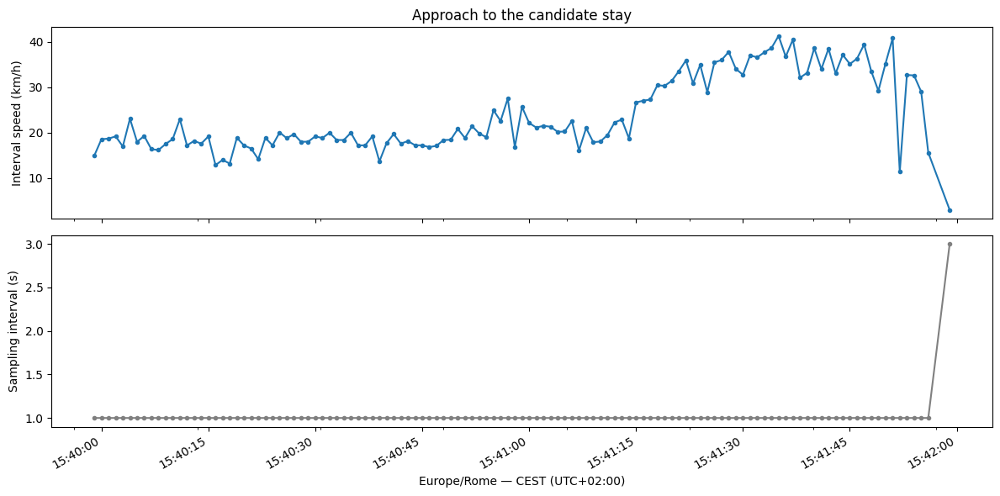

In [39]:
# Calculate speed from consecutive positions and timestamps.
trajectory.add_speed(
    overwrite=True,
    name="speed_kmh",
    units=("km", "h"),
)

# Calculate the elapsed seconds between consecutive observations.
trajectory.df["interval_s"] = (
    trajectory.df.index.to_series()
    .diff()
    .dt.total_seconds()
)

# The first observation has no preceding position.
trajectory.df.loc[trajectory.df.index[0], "speed_kmh"] = np.nan

# Identify intervals longer than 0 and no longer than 5 seconds.
trajectory.df["short_interval"] = (
    trajectory.df["interval_s"].gt(0)
    & trajectory.df["interval_s"].le(5)
)

# Preserve all speeds, but exclude long intervals from the detailed plot.
trajectory.df["short_interval_speed_kmh"] = (
    trajectory.df["speed_kmh"]
    .where(trajectory.df["short_interval"])
)

# Create readable Italian timestamps from the UTC analysis index.
trajectory.df["time_Italy"] = (
    pd.to_datetime(trajectory.df.index, utc=True)
    .tz_convert("Europe/Rome")
    .strftime("%d/%m/%Y %H:%M:%S %Z")
)

# Select two minutes before the candidate stay and 15 seconds after it.
approach = trajectory.df.loc[
    wait_start - pd.Timedelta(minutes=2):
    wait_start + pd.Timedelta(seconds=15)
].copy()

# Calculate the change between consecutive interval-speed estimates.
approach["speed_change_kmh"] = approach["speed_kmh"].diff()

# Compare speeds only when both sampling intervals are short.
valid_pair = (
    approach["short_interval"]
    & approach["short_interval"].shift(1, fill_value=False)
)

approach["speed_change_kmh"] = (
    approach["speed_change_kmh"].where(valid_pair)
)

# Inspect the last observations around the beginning of the stay.
display(
    approach[
        [
            "time_Italy",
            "sequence",
            "speed_kmh",
            "interval_s",
            "speed_change_kmh",
        ]
    ].tail(25)
)

# Convert a plotting copy to Italian local time.
# Keep the original trajectory index unchanged.
local_approach = approach.copy()
local_approach.index = (
    pd.to_datetime(local_approach.index, utc=True)
    .tz_convert("Europe/Rome")
)

# Plot speed and sampling intervals on the same time axis.
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 6),
    sharex=True,
)

local_approach["short_interval_speed_kmh"].plot(
    ax=axes[0],
    marker=".",
)
axes[0].set_ylabel("Interval speed (km/h)")
axes[0].set_title("Approach to the candidate stay")

local_approach["interval_s"].plot(
    ax=axes[1],
    marker=".",
    color="gray",
)
axes[1].set_ylabel("Sampling interval (s)")
axes[1].set_xlabel("Europe/Rome — CEST (UTC+02:00)")

plt.tight_layout()
plt.show()

## 11. Choose an explicit candidate event time

Use the strongest sampled speed decrease in the minute before the stay as a starting hypothesis. Display the other candidates and the rebound afterwards. The chosen t0 is an analysis reference, not a verified impact time. Change it when external evidence supports another instant.

**Colab AI prompt:** Rank negative speed changes in the minute before wait_start. Select the largest decrease as suggested_t0, then define an editable t0. Report the preceding and following samples and the last five-second interval around the reference point.

In [40]:
drop_candidates = approach.loc[wait_start - pd.Timedelta(seconds=60):wait_start]
drop_candidates = drop_candidates.loc[drop_candidates["speed_change_kmh"] < 0]
if drop_candidates.empty:
    raise ValueError("No eligible speed decrease: inspect the samples manually.")
display(drop_candidates.nsmallest(5, "speed_change_kmh")[["time_Italy", "speed_kmh", "speed_change_kmh", "interval_s"]])
suggested_t0 = drop_candidates["speed_change_kmh"].idxmin()
t0 = suggested_t0  # Replace with a documented time if you have independent evidence.
print("Candidate reference UTC:", t0)
print("Candidate reference Italy:", t0.tz_localize("UTC").tz_convert("Europe/Rome"))
display(trajectory.df.loc[t0 - pd.Timedelta(seconds=5):t0 + pd.Timedelta(seconds=8),
                         ["time_Italy", "sequence", "speed_kmh", "interval_s", "longitude", "latitude"]])

,time_Italy,speed_kmh,speed_change_kmh,interval_s
time,,,,
2021-10-12 13:41:52,12/10/2021 15:41:52 CEST,11.387270,-29.448728,1.0
2021-10-12 13:41:56,12/10/2021 15:41:56 CEST,15.630765,-13.439151,1.0
2021-10-12 13:41:59,12/10/2021 15:41:59 CEST,3.015281,-12.615484,3.0
2021-10-12 13:41:38,12/10/2021 15:41:38 CEST,32.129704,-8.389074,1.0
2021-10-12 13:41:07,12/10/2021 15:41:07 CEST,16.125937,-6.493649,1.0


Candidate reference UTC: 2021-10-12 13:41:52
Candidate reference Italy: 2021-10-12 15:41:52+02:00


,time_Italy,sequence,speed_kmh,interval_s,longitude,latitude
time,,,,,,
2021-10-12 13:41:47,12/10/2021 15:41:47 CEST,5057,39.460021,1.0,10.842102,45.888540
2021-10-12 13:41:48,12/10/2021 15:41:48 CEST,5058,33.560328,1.0,10.842219,45.888559
2021-10-12 13:41:49,12/10/2021 15:41:49 CEST,5059,29.242950,1.0,10.842322,45.888546
2021-10-12 13:41:50,12/10/2021 15:41:50 CEST,5060,35.253657,1.0,10.842439,45.888579
2021-10-12 13:41:51,12/10/2021 15:41:51 CEST,5061,40.835999,1.0,10.842554,45.888642
2021-10-12 13:41:52,12/10/2021 15:41:52 CEST,5062,11.387270,1.0,10.842583,45.888662
2021-10-12 13:41:53,12/10/2021 15:41:53 CEST,5063,32.735897,1.0,10.842633,45.888736
2021-10-12 13:41:54,12/10/2021 15:41:54 CEST,5064,32.642217,1.0,10.842679,45.888811
2021-10-12 13:41:55,12/10/2021 15:41:55 CEST,5065,29.069916,1.0,10.842693,45.888883


A sharp sampled speed decrease is useful for locating an interval to inspect. It is not a crash sensor. A GPS-derived interval speed can drop and rebound because of measurement noise; an actual impact may occur between observations. We therefore examine the whole local sequence and the known account together. We do not calculate impact force from these data.

## 12. What was the speed 5, 10, 15, 30 and 60 seconds earlier?

For each requested time, use the latest available observation at or before it. Show the actual timestamp, age and duration of the speed interval. This avoids silently substituting a future or distant observation. Retain a value only if it ends within 5 seconds of the target and spans at most 5 seconds.

**Colab AI prompt:** Build a five-row pre-event table for offsets 5,10,15,30,60 seconds. Include target UTC, sample UTC and Italy time, sample age, interval duration, interval speed and a support flag. Explain that each speed is an interval estimate, not an instantaneous measurement.

In [41]:
pre_event_rows = []
for seconds_before in [5, 10, 15, 30, 60]:
    target = t0 - pd.Timedelta(seconds=seconds_before)
    available = trajectory.df.loc[:target]
    if available.empty:
        pre_event_rows.append({"seconds_before_t0": seconds_before, "target_UTC": target,
                               "supported": False})
        continue
    sample_time = available.index[-1]
    sample = available.iloc[-1]
    age_s = (target - sample_time).total_seconds()
    supported = age_s <= 5 and 0 < sample["interval_s"] <= 5
    pre_event_rows.append({"seconds_before_t0": seconds_before, "target_UTC": target,
        "sample_UTC": sample_time,
        "sample_Italy": sample_time.tz_localize("UTC").tz_convert("Europe/Rome"),
        "sample_age_s": age_s, "interval_start_UTC": sample_time - pd.Timedelta(seconds=sample["interval_s"]),
        "interval_s": sample["interval_s"], "speed_kmh": sample["speed_kmh"] if supported else np.nan,
        "supported": supported})
pre_event_speeds = pd.DataFrame(pre_event_rows)
pre_event_speeds["target_Italy"] = pd.to_datetime(pre_event_speeds["target_UTC"]).dt.tz_localize("UTC").dt.tz_convert("Europe/Rome")
display(pre_event_speeds[["seconds_before_t0", "target_Italy", "sample_Italy", "sample_age_s",
                          "interval_s", "speed_kmh", "supported"]].round({"speed_kmh": 1}))

,seconds_before_t0,target_Italy,sample_Italy,sample_age_s,interval_s,speed_kmh,supported
0,5,2021-10-12 15:41:47+02:00,2021-10-12 15:41:47+02:00,0.0,1.0,39.5,True
1,10,2021-10-12 15:41:42+02:00,2021-10-12 15:41:42+02:00,0.0,1.0,38.5,True
2,15,2021-10-12 15:41:37+02:00,2021-10-12 15:41:37+02:00,0.0,1.0,40.5,True
3,30,2021-10-12 15:41:22+02:00,2021-10-12 15:41:22+02:00,0.0,1.0,35.9,True
4,60,2021-10-12 15:40:52+02:00,2021-10-12 15:40:52+02:00,0.0,1.0,21.5,True


## 13. A different question: average speed over the last N seconds

Speed at an earlier sample and average speed during a preceding window answer different questions. For each window ending at t0, sum the supported segment distances and divide by supported time. Clip boundary-crossing intervals proportionally, assuming uniform speed within each short segment. Report the fraction of each window actually supported.

**Colab AI prompt:** Calculate time-weighted mean speed over the last 5,10,15,30,60 seconds before t0. Include only intervals no longer than 5 seconds; clip partial overlaps. Do not use an arithmetic mean when intervals differ, and do not report uncovered time as zero speed.

In [42]:
intervals = trajectory.df[["speed_kmh", "interval_s"]].copy()
intervals["end"] = intervals.index
intervals["start"] = intervals["end"] - pd.to_timedelta(intervals["interval_s"], unit="s")
window_rows = []
for seconds in [5, 10, 15, 30, 60]:
    start = t0 - pd.Timedelta(seconds=seconds)
    # Clip each source interval to the requested time window.
    overlap_start = intervals["start"].clip(lower=start)
    overlap_end = intervals["end"].clip(upper=t0)
    overlap_s = (overlap_end - overlap_start).dt.total_seconds().clip(lower=0)
    usable = intervals["interval_s"].between(0, 5, inclusive="right") & intervals["speed_kmh"].notna()
    overlap_s = overlap_s.where(usable, 0)
    supported_s = overlap_s.sum()
    # speed × time gives distance; this is a time-weighted mean, not a sample mean.
    mean_kmh = (intervals["speed_kmh"].fillna(0) * overlap_s).sum() / supported_s if supported_s else np.nan
    window_rows.append({"window_before_t0_s": seconds, "supported_s": supported_s,
                       "coverage_fraction": supported_s / seconds, "mean_speed_kmh": mean_kmh})
pre_event_windows = pd.DataFrame(window_rows)
display(pre_event_windows.round(2))

,window_before_t0_s,supported_s,coverage_fraction,mean_speed_kmh
0,5,5.0,1.0,30.06
1,10,10.0,1.0,33.15
2,15,15.0,1.0,33.87
3,30,30.0,1.0,34.93
4,60,60.0,1.0,29.22


## 14. Map the local evidence

Place the reference point, the earlier sample locations and the start of the candidate stay on the same map. Their separation matters: they are not interchangeable event coordinates. A sampled position near the reference time is not an independently surveyed impact point.

**Colab AI prompt:** Map the two-minute approach on HOT OSM, add the candidate t0 point, the last available position for each requested offset and the candidate-stay start. Label their actual UTC times and estimated interval speeds.

In [43]:
local_points = approach.to_crs(4326)
m = local_points.explore(tiles="OpenStreetMap.HOT", column="speed_kmh", cmap="viridis",
    legend=True, tooltip=["time_Italy", "sequence", "speed_kmh", "interval_s"], marker_kwds={"radius": 3})
for row in pre_event_speeds.itertuples():
    if row.supported:
        location = trajectory.df.loc[row.sample_UTC:row.sample_UTC].to_crs(4326).geometry.iloc[0]
        folium.CircleMarker([location.y, location.x], radius=6, color="blue", fill=True,
            tooltip=f"{row.seconds_before_t0} s before t0; sample {row.sample_Italy}; {row.speed_kmh:.1f} km/h").add_to(m)
for label, timestamp, color in [("Candidate event reference", t0, "red"),
                                ("Candidate stay begins", wait_start, "orange")]:
    location = trajectory.get_position_at(timestamp, method="nearest")
    marker = gpd.GeoSeries([location], crs=trajectory.df.crs).to_crs(4326).iloc[0]
    folium.Marker([marker.y, marker.x], tooltip=f"{label}: {timestamp.tz_localize('UTC').tz_convert('Europe/Rome')}",
        icon=folium.Icon(color=color)).add_to(m)
display(m)

## 15. Inspect waiting and resumed movement

After the long stay, compare the spatial path, interval speeds and sampling. The known story identifies an ambulance transfer; a GPS speed increase alone cannot identify the vehicle, its arrival time or loading time.

**Colab AI prompt:** Inspect five minutes before and ten minutes after wait_end. Plot short-interval speeds in Europe/Rome time and show minute-level medians and counts of supporting intervals. Do not interpolate empty minutes.

,median,max,count
time,,,
2021-10-12 16:24:00+02:00,8.710404,18.123352,14
2021-10-12 16:25:00+02:00,19.916028,43.292592,30
2021-10-12 16:26:00+02:00,32.523656,60.643960,35
2021-10-12 16:27:00+02:00,37.237763,87.473128,35
2021-10-12 16:28:00+02:00,53.843489,81.161487,58
2021-10-12 16:29:00+02:00,48.227385,107.446806,39
2021-10-12 16:30:00+02:00,24.655777,73.259752,58
2021-10-12 16:31:00+02:00,51.483093,56.723634,58
2021-10-12 16:32:00+02:00,37.460866,50.534251,60


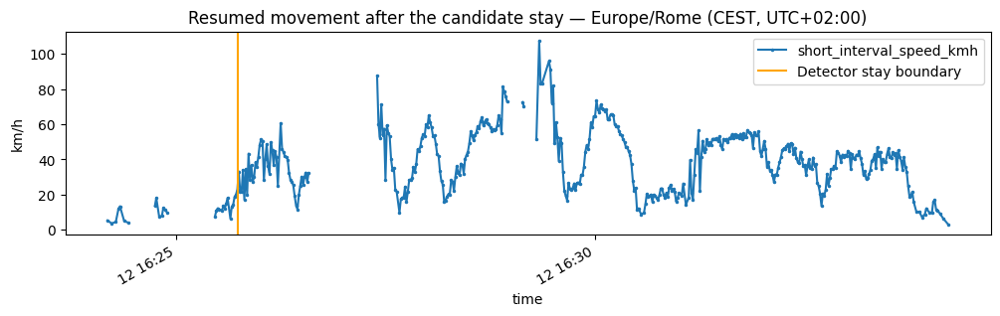

In [44]:
departure = trajectory.df.loc[wait_end - pd.Timedelta(minutes=5):
                              wait_end + pd.Timedelta(minutes=10)].copy()
local_departure = departure.copy()
local_departure.index = local_departure.index.tz_localize("UTC").tz_convert("Europe/Rome")
minute_summary = local_departure["short_interval_speed_kmh"].resample("1min").agg(["median", "max", "count"])
display(minute_summary)
local_departure["short_interval_speed_kmh"].plot(figsize=(12, 3), marker=".", markersize=3,
    title="Resumed movement after the candidate stay — Europe/Rome (CEST, UTC+02:00)")
plt.axvline(wait_end.tz_localize("UTC").tz_convert("Europe/Rome"), color="orange", label="Detector stay boundary")
plt.ylabel("km/h"); plt.legend(); plt.show()
display(departure.to_crs(4326).explore(tiles="OpenStreetMap.HOT", column="speed_kmh",
    cmap="viridis", legend=True, tooltip=["time_Italy", "sequence", "speed_kmh", "interval_s"]))

## 16. Show the sequence of phases

Colour the route using provisional boundaries: ride before t0, local transition, candidate stay and movement after the stay. These labels are an interpretation of the known account. Keep the boundaries editable. Do not draw a continuous line across recording gaps longer than 5 seconds.

**Colab AI prompt:** Build line runs within each provisional phase, split at timestamp gaps over 5 seconds and render the resulting lines on HOT OSM. Include the sampled positions during the candidate stay and the recording endpoint, without labelling the endpoint as verified hospital admission.

In [45]:
from shapely.geometry import LineString
phase_ranges = [
    ("Ride before candidate event", trajectory.get_start_time(), t0, "blue"),
    ("Local transition", t0, wait_start, "red"),
    ("Candidate stay", wait_start, wait_end, "orange"),
    ("Movement after stay (known transfer)", wait_end, trajectory.get_end_time(), "purple"),
]
m = folium.Map(location=[45.89, 10.84], tiles="OpenStreetMap.HOT", zoom_start=12)
for label, start, end, color in phase_ranges:
    points = trajectory.df.loc[start:end]
    # A new line run begins after a temporal gap: missing movement stays missing.
    run_id = points.index.to_series().diff().dt.total_seconds().gt(5).cumsum()
    lines = [LineString(run.geometry.tolist()) for _, run in points.groupby(run_id) if len(run) >= 2]
    if lines:
        layer = gpd.GeoDataFrame({"phase": [label] * len(lines)}, geometry=lines, crs=points.crs)
        layer.to_crs(4326).explore(m=m, name=label, color=color, style_kwds={"weight": 4})
wait_points.to_crs(4326).explore(m=m, name="Recorded stay positions", color="orange",
    tooltip=["time_Italy", "sequence", "interval_s"], marker_kwds={"radius": 4})
endpoint = geo_df.geometry.iloc[-1]
folium.Marker([endpoint.y, endpoint.x], tooltip="Recording endpoint; check against the known destination").add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
bounds = geo_df.total_bounds
m.fit_bounds([[bounds[1], bounds[0]], [bounds[3], bounds[2]]])
display(m)

## 17. How sensitive is the reconstruction?

Compare 30, 60 and 100 m stop diameters. Then vary the candidate reference by a few seconds: this changes what “five seconds before” means. Show the sensitivity rather than selecting whichever timing produces the strongest story.

**Colab AI prompt:** For each stop diameter, report the longest candidate stay start, end and elapsed duration. Compare estimated speeds five seconds before t0-5, t0 and t0+5 seconds, displaying the actual selected sample and interval duration.

In [46]:
stop_sensitivity = []
for diameter in [30, 60, 100]:
    candidates = detector.get_stop_points(max_diameter=diameter, min_duration=timedelta(seconds=60))
    longest = candidates.sort_values("duration_s", ascending=False).iloc[0]
    stop_sensitivity.append({"diameter_m": diameter, "start_UTC": longest["start_time"],
        "end_UTC": longest["end_time"], "elapsed_min": longest["duration_s"] / 60})
stop_sensitivity_table = pd.DataFrame(stop_sensitivity)
for column in ["start_UTC", "end_UTC"]:
    stop_sensitivity_table[column.replace("UTC", "Italy")] = pd.to_datetime(stop_sensitivity_table[column]).dt.tz_localize("UTC").dt.tz_convert("Europe/Rome")
display(stop_sensitivity_table[["diameter_m", "start_Italy", "end_Italy", "elapsed_min"]])
timing_sensitivity = []
for shift_s in [-5, 0, 5]:
    reference = t0 + pd.Timedelta(seconds=shift_s)
    target = reference - pd.Timedelta(seconds=5)
    sample = trajectory.df.loc[:target].iloc[-1]
    age_s = (target - sample.name).total_seconds()
    supported = age_s <= 5 and 0 < sample["interval_s"] <= 5
    timing_sensitivity.append({"reference_shift_s": shift_s, "reference_UTC": reference,
        "sample_UTC": sample.name, "interval_s": sample["interval_s"],
        "speed_5s_before_kmh": sample["speed_kmh"] if supported else np.nan})
timing_table = pd.DataFrame(timing_sensitivity)
for column in ["reference_UTC", "sample_UTC"]:
    timing_table[column.replace("UTC", "Italy")] = pd.to_datetime(timing_table[column]).dt.tz_localize("UTC").dt.tz_convert("Europe/Rome")
display(timing_table[["reference_shift_s", "reference_Italy", "sample_Italy", "interval_s", "speed_5s_before_kmh"]].round(1))

,diameter_m,start_Italy,end_Italy,elapsed_min
0,30,2021-10-12 15:41:59+02:00,2021-10-12 16:24:45+02:00,42.766667
1,60,2021-10-12 15:41:59+02:00,2021-10-12 16:25:44+02:00,43.750000
2,100,2021-10-12 15:41:59+02:00,2021-10-12 16:25:53+02:00,43.900000


,reference_shift_s,reference_Italy,sample_Italy,interval_s,speed_5s_before_kmh
0,-5,2021-10-12 15:41:47+02:00,2021-10-12 15:41:42+02:00,1.0,38.5
1,0,2021-10-12 15:41:52+02:00,2021-10-12 15:41:47+02:00,1.0,39.5
2,5,2021-10-12 15:41:57+02:00,2021-10-12 15:41:52+02:00,1.0,11.4


## 18. Write an evidence-based account

Build the explanation in three columns:

| Recorded / computed evidence | Interpretation given the known account | What remains unresolved |
|---|---|---|
| Sequence of positions and interval speeds | Bicycle journey | Detailed activity between samples |
| Local sampled speed decrease followed by a long spatial stay | Candidate incident interval and waiting location | Exact impact instant, mechanism and force |
| Sparse positions close together during a long elapsed interval | Consistent with a prolonged wait | Movement and events during recording gaps |
| Sustained movement resumes along another route | Transfer, identified as ambulance by the instructor's account | Ambulance arrival and loading time |
| Device recording ends at a mapped location | Compare with the known emergency-department destination | Hospital admission time |

Report the chosen reference time as a **candidate** and give its timezone. Describe both the speed interval used and its temporal support. A sensible conclusion can be precise about measured changes while remaining cautious about the event they represent.

**Exercise:** explain the sequence using the maps, the pre-event tables and the gap inspection. State which facts came from the GPS and which came from the instructor. What additional evidence would narrow the incident interval?

In [47]:
# Export derived tables without replacing the source GPX.
pre_event_speeds.to_csv(DATA / "incident_pre_event_samples.csv", index=False)
pre_event_windows.to_csv(DATA / "incident_pre_event_windows.csv", index=False)
trajectory.df.drop(columns="geometry").to_csv(DATA / "trip_with_derived_speed.csv")
(DATA / "incident_analysis_choices.json").write_text(json.dumps({
    "source": gpx_url, "recording_segment": [0, 0], "analysis_timezone": "UTC",
    "display_timezone": "Europe/Rome", "stop_diameter_m": 60,
    "stop_minimum_s": 60, "candidate_t0_UTC": str(t0),
    "candidate_stay_UTC": [str(wait_start), str(wait_end)],
    "short_interval_limit_s": 5,
    "context": "Instructor account: cycling incident, wait, ambulance transfer to emergency department",
    "reference_status": "Candidate from sampled speed decrease; not an independently verified impact time"
}, indent=2))

679

## Optional appendix · Simplification is for representation

A generalised line may help presentation but changes the observations used to calculate distance and speed. Run this comparison after the event analysis, keeping the original trajectory unchanged. A 10 m tolerance is in metres because the working CRS is UTM.

**Colab AI prompt:** Use DouglasPeuckerGeneralizer at 10 metres and compare point count and length with the original. Do not recompute the incident's approach speed from the simplified trajectory.

In [48]:
# EPSG:32632 uses metres: tolerance=10 therefore means 10 metres.
generalised = mpd.DouglasPeuckerGeneralizer(trajectory).generalize(tolerance=10)
display(pd.DataFrame([
    {"version": "original", "observations": len(trajectory.df), "length_m": trajectory.get_length()},
    {"version": "generalised 10m", "observations": len(generalised.df), "length_m": generalised.get_length()},
]))
m = trajectory.explore(tiles="OpenStreetMap.HOT", color="blue", name="Original")
generalised.explore(m=m, color="red", name="Generalised 10m")
folium.LayerControl().add_to(m)
display(m)

,version,observations,length_m
0,original,5532,40310.238380
1,generalised 10m,427,39099.912087
